## 01 — Setup and Shared Storage

In [1]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
# Optional shared storage: mount Drive for persistent files across Colab notebooks.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/CAI470_Project')
else:
    ROOT = Path.cwd() / 'CAI470_Project'
RAW = ROOT / 'raw'
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
for p in [RAW, OUT, FIG]: p.mkdir(parents=True, exist_ok=True)
print('Shared project folder:', ROOT)

Mounted at /content/drive
Shared project folder: /content/drive/MyDrive/CAI470_Project


## 02 — Load Original Train and Test

In [2]:
TRAIN_NAME = 'UNSW_NB15_training-set.csv'
TEST_NAME = 'UNSW_NB15_testing-set.csv'
BASE_URL = 'https://raw.githubusercontent.com/jamshaid120/UNSW_NB15-Complete-dataset/main/'
# Mirror of the official fixed UNSW-NB15 train/test partition.
# If downloading is blocked, upload the two ORIGINAL CSV files from UNSW here.
for name in [TRAIN_NAME, TEST_NAME]:
    path = RAW / name
    if not path.is_file():
        try:
            print('Downloading:', name)
            import requests
            response = requests.get(BASE_URL + name, timeout=120)
            response.raise_for_status()
            path.write_bytes(response.content)
        except Exception as e:
            print('Automatic download unavailable:', type(e).__name__)
            if 'google.colab' in sys.modules:
                from google.colab import files as colab_files
                print('Upload ORIGINAL:', name)
                uploaded = colab_files.upload()
                match = next((v for k,v in uploaded.items() if Path(k).name.lower()==name.lower()), None)
                if match is None:
                    raise FileNotFoundError(f'Please upload {name}; provided files: {list(uploaded)}')
                path.write_bytes(match)
            else:
                raise FileNotFoundError(f'Download or place {name} into {RAW}') from e
    if path.stat().st_size < 1_000_000:
        raise ValueError(f'{name} is unexpectedly small; check the source CSV.')
train = pd.read_csv(RAW/TRAIN_NAME, low_memory=False)
test = pd.read_csv(RAW/TEST_NAME, low_memory=False)
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()
assert len(train) == 175341 and len(test) == 82332, (train.shape, test.shape)
assert list(train.columns) == list(test.columns), 'Train/test columns do not match.'
assert {'id','attack_cat','label'}.issubset(train.columns)
assert set(pd.to_numeric(train.label).unique()) <= {0,1}
assert set(pd.to_numeric(test.label).unique()) <= {0,1}
print('Training:', train.shape, 'Testing:', test.shape)

Training: (175341, 45) Testing: (82332, 45)


## 03 — Define Features and Labels

In [3]:
TARGET = 'label'
EXCLUDE = ['id', 'attack_cat', TARGET]
FEATURES = [c for c in train.columns if c not in EXCLUDE]
CAT = [c for c in ['proto', 'service', 'state'] if c in FEATURES]
NUM = [c for c in FEATURES if c not in CAT]
assert len(FEATURES) == 42, f'Expected 42 features, found {len(FEATURES)}'
for df in (train,test):
    for col in CAT:
        df[col] = df[col].fillna('Unknown').astype(str).str.strip()
    for col in NUM:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].replace([np.inf,-np.inf], np.nan)
y_train = train[TARGET].astype(int)
y_test = test[TARGET].astype(int)
X_train, X_test = train[FEATURES].copy(), test[FEATURES].copy()
assert not set(EXCLUDE).intersection(X_train.columns)
assert list(X_train.columns) == list(X_test.columns)
print('Features:',len(FEATURES),'Numerical:',len(NUM),'Categorical:',CAT)

Features: 42 Numerical: 39 Categorical: ['proto', 'service', 'state']


## 04 — Preprocessing Pipelines

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
# Sparse encoding: avoids creating a very large dense design matrix.
num_scaled=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
cat_onehot=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))])
pre_scaled=ColumnTransformer([('num',num_scaled,NUM),('cat',cat_onehot,CAT)],sparse_threshold=1.0)
pre_trees=ColumnTransformer([('num',SimpleImputer(strategy='median'),NUM),('cat',cat_onehot,CAT)],sparse_threshold=1.0)
# HistGradientBoosting requires dense numerical input; ordinal categories are marked as categorical.
cat_ordinal=Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))])
pre_hgb=ColumnTransformer([('num',SimpleImputer(strategy='median'),NUM),('cat',cat_ordinal,CAT)],sparse_threshold=0.0)
print('Numeric:',len(NUM),'Categorical:',len(CAT))

Numeric: 39 Categorical: 3


## 05 — Initialize Four Classifiers

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
models = {
  'Logistic Regression': Pipeline([('preprocess',pre_scaled),('model',LogisticRegression(max_iter=500,solver='liblinear',class_weight='balanced',random_state=SEED))]),
  'Decision Tree': Pipeline([('preprocess',pre_trees),('model',DecisionTreeClassifier(max_depth=22,min_samples_leaf=5,random_state=SEED))]),
  'Random Forest': Pipeline([('preprocess',pre_trees),('model',RandomForestClassifier(n_estimators=100,max_depth=24,min_samples_leaf=2,n_jobs=-1,random_state=SEED))]),
  'HistGradientBoosting': Pipeline([('preprocess',pre_hgb),('model',HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=31,learning_rate=0.08,l2_regularization=1.0,categorical_features=list(range(len(NUM),len(NUM)+len(CAT))),random_state=SEED))])
}
print('Configured:',list(models))

Configured: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'HistGradientBoosting']


## 06 — Model Training

In [6]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
import time

# Internal validation split from official training only
X_inner, X_val, y_inner, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=SEED
)

print("Inner training:", len(X_inner))
print("Validation:", len(X_val))
print("Official test untouched:", len(X_test))

validation_rows = []

for name, pipeline in models.items():

    print("Validating:", name, flush=True)

    candidate = clone(pipeline)
    candidate.fit(X_inner, y_inner)

    val_pred = candidate.predict(X_val)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "FP": int(fp),
        "FN": int(fn)
    })

validation_results = pd.DataFrame(
    validation_rows
).sort_values(
    ["F1-score", "Recall"],
    ascending=False
).reset_index(drop=True)

best_name = validation_results.iloc[0]["Model"]

print("Best model selected by Validation:", best_name)
display(validation_results.round(4))

validation_results.to_csv(
    OUT / "validation_model_comparison.csv",
    index=False
)

# Refit all models on the entire official training set
fit_times = {}

for name, model in models.items():

    print("Refitting:", name, flush=True)
    start = time.perf_counter()

    model.fit(X_train, y_train)

    fit_times[name] = round(
        time.perf_counter() - start, 2
    )

    print("Completed:", name)

best_model = models[best_name]

print("All four models trained.")
print("Selected model:", best_name)
print("Ready for final test evaluation.")


Inner training: 140272
Validation: 35069
Official test untouched: 82332
Validating: Logistic Regression
Validating: Decision Tree
Validating: Random Forest
Validating: HistGradientBoosting
Best model selected by Validation: Random Forest


,Model,Accuracy,Precision,Recall,F1-score,FP,FN
0,Random Forest,0.9584,0.9584,0.9814,0.9698,1017,443
1,HistGradientBoosting,0.9573,0.9617,0.9762,0.9689,929,568
2,Decision Tree,0.9499,0.9633,0.9630,0.9632,875,883
3,Logistic Regression,0.9326,0.9502,0.9509,0.9505,1190,1173


Refitting: Logistic Regression
Completed: Logistic Regression
Refitting: Decision Tree
Completed: Decision Tree
Refitting: Random Forest
Completed: Random Forest
Refitting: HistGradientBoosting
Completed: HistGradientBoosting
All four models trained.
Selected model: Random Forest
Ready for final test evaluation.


## 07 — Predictions and Metrics

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score
records=[]; pred_frame=pd.DataFrame({'id':test['id'].to_numpy(),'actual':y_test.to_numpy(),'attack_cat':test['attack_cat'].fillna('Normal').astype(str).to_numpy()})
for name, model in models.items():
    pred=model.predict(X_test)
    proba=model.predict_proba(X_test)[:,1]
    tn,fp,fn,tp=confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    records.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1-score':f1_score(y_test,pred,zero_division=0),'ROC-AUC':roc_auc_score(y_test,proba),'PR-AUC':average_precision_score(y_test,proba),'FP':int(fp),'FN':int(fn),'TP':int(tp),'TN':int(tn),'Fit seconds':fit_times[name]})
    tag=name.lower().replace(' ','_')
    pred_frame[f'{tag}_prediction']=pred
    pred_frame[f'{tag}_probability']=proba
results=pd.DataFrame(records).sort_values(['F1-score','Recall'],ascending=False)
display(results.round(4))
assert len(results)==4

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FP,FN,TP,TN,Fit seconds
3,HistGradientBoosting,0.8729,0.8210,0.9835,0.8950,0.9855,0.9895,9719,747,44585,27281,12.99
2,Random Forest,0.8652,0.8086,0.9893,0.8899,0.9823,0.9868,10616,483,44849,26384,114.73
1,Decision Tree,0.8680,0.8269,0.9615,0.8891,0.9106,0.8806,9125,1746,43586,27875,13.04
0,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9560,0.9666,10400,3145,42187,26600,15.63


## 08 — Comparison Charts

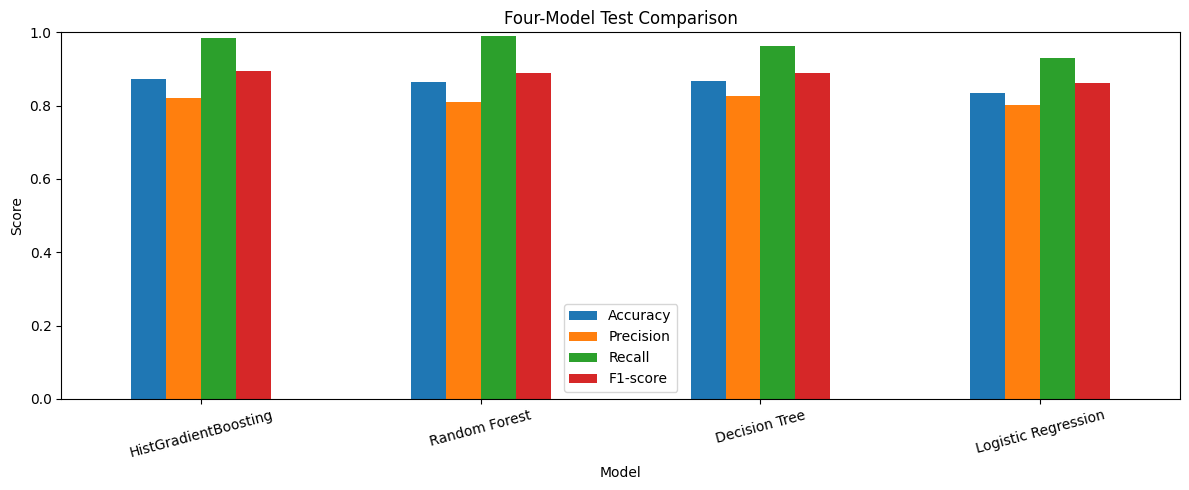

In [8]:
ax=results.set_index('Model')[['Accuracy','Precision','Recall','F1-score']].plot.bar(figsize=(12,5),ylim=(0,1),rot=15)
ax.set_title('Four-Model Test Comparison');ax.set_ylabel('Score');plt.tight_layout();plt.savefig(FIG/'four_model_comparison.png',dpi=150);plt.show()

## 09 — Four Confusion Matrices

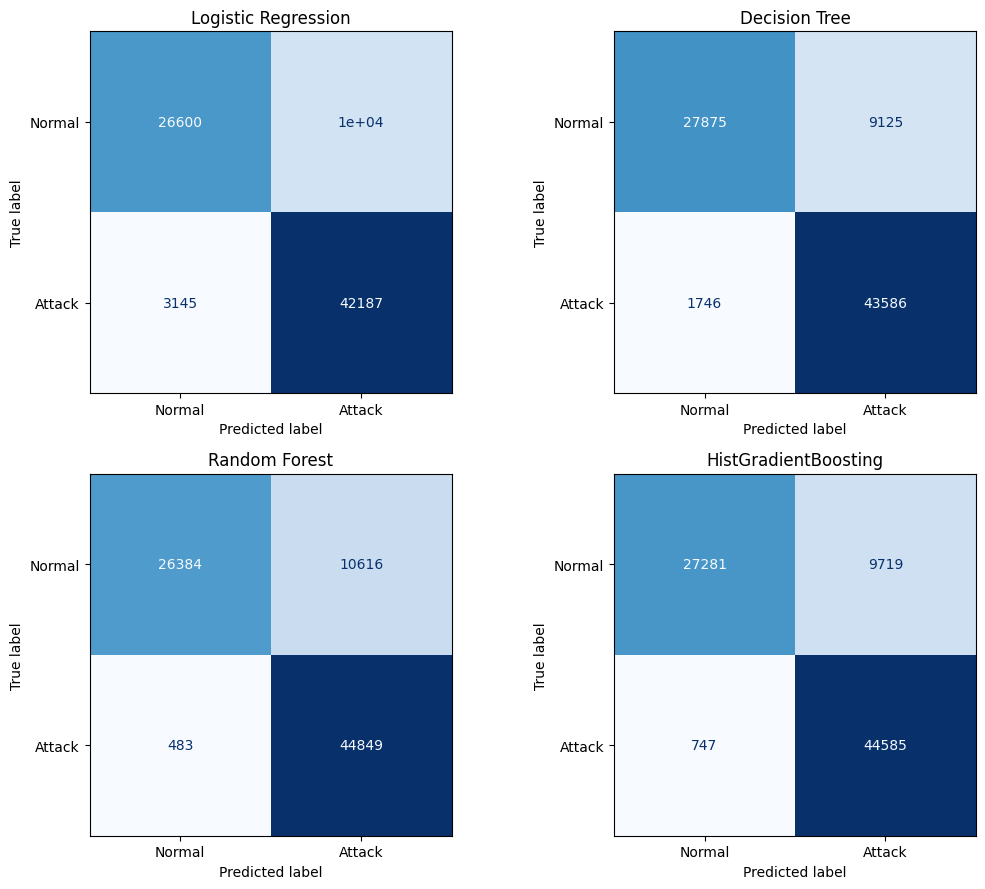

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay
fig,axs=plt.subplots(2,2,figsize=(11,9))
for ax,(name,model) in zip(axs.flat,models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,model.predict(X_test),display_labels=['Normal','Attack'],cmap='Blues',colorbar=False,ax=ax)
    ax.set_title(name)
plt.tight_layout();plt.savefig(FIG/'confusion_matrices.png',dpi=150);plt.show()

## 10 — Choose Best Model

In [10]:

# Model selected using validation, not test scores

best_model = models[best_name]

selected_test_results = results.set_index(
    "Model"
).loc[best_name]

print("Validation-selected model:", best_name)

print(
    "Final Test F1:",
    round(float(selected_test_results["F1-score"]), 4)
)

print(
    "Final Test Recall:",
    round(float(selected_test_results["Recall"]), 4)
)

print(
    "Final Test False Negatives:",
    int(selected_test_results["FN"])
)

print(
    "The official test set was not used "
    "to choose the best model."
)

selection_info = {
    "best_model": best_name,
    "selection_metric": "Validation F1",
    "validation_rows": len(X_val),
    "official_test_rows": len(X_test)
}

(OUT / "best_model.json").write_text(
    json.dumps(selection_info, indent=2),
    encoding="utf-8"
)


Validation-selected model: Random Forest
Final Test F1: 0.8899
Final Test Recall: 0.9893
Final Test False Negatives: 483
The official test set was not used to choose the best model.


133

## 11 — Global Explainability

Permutation importance for: Random Forest on 1000 training samples


,Feature,Mean F1 decrease,Std
2,service,0.011946,0.000902
35,ct_dst_src_ltm,0.010259,0.002165
24,synack,0.009800,0.000336
27,dmean,0.009736,0.001492
6,sbytes,0.008580,0.000909
40,ct_srv_dst,0.007147,0.001529
26,smean,0.005886,0.001190
9,sttl,0.005150,0.000943
23,tcprtt,0.005121,0.000614
30,ct_srv_src,0.004661,0.001305


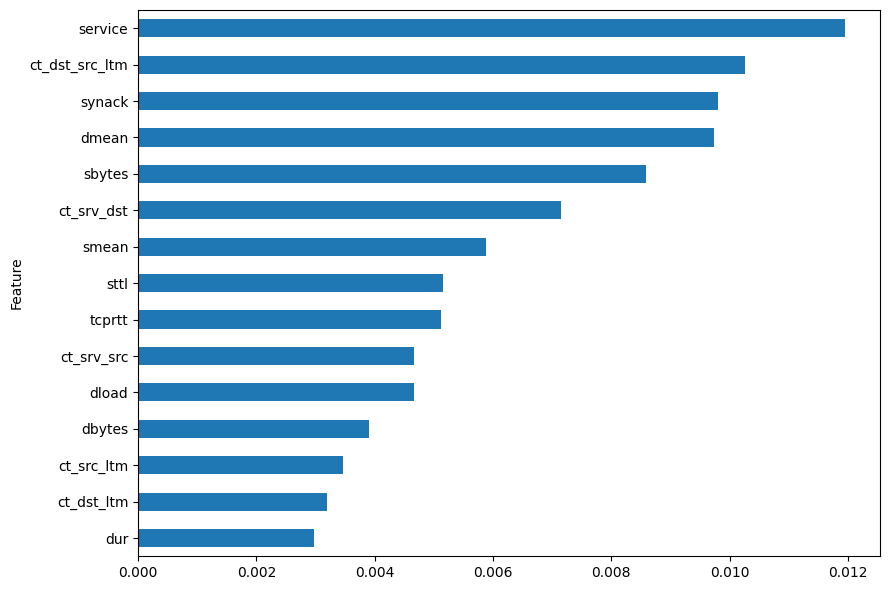

In [11]:
from sklearn.inspection import permutation_importance
# Explanations on a held-out TRAINING subset only, never used to modify the models.
from sklearn.model_selection import train_test_split
_,x_explain,_,y_explain=train_test_split(X_train,y_train,test_size=0.06,random_state=17,stratify=y_train)
x_explain=x_explain.iloc[:min(1000,len(x_explain))]
y_explain=y_explain.loc[x_explain.index]
print('Permutation importance for:',best_name,'on',len(x_explain),'training samples')
perm=permutation_importance(best_model,x_explain,y_explain,n_repeats=3,random_state=SEED,scoring='f1',n_jobs=1)
importance=pd.DataFrame({'Feature':FEATURES,'Mean F1 decrease':perm.importances_mean,'Std':perm.importances_std}).sort_values('Mean F1 decrease',ascending=False)
display(importance.head(15))
importance.to_csv(OUT/'best_model_permutation_importance.csv',index=False)
importance.head(15).sort_values('Mean F1 decrease').plot.barh(x='Feature',y='Mean F1 decrease',legend=False,figsize=(9,6));plt.tight_layout();plt.savefig(FIG/'feature_importance.png',dpi=150);plt.show()

In [14]:
%pip install -q shap


SHAP model: Random Forest
Explained class: Attack = 1
Explained samples: 12


,Feature,Mean absolute SHAP
6,num__sttl,0.070820
7,num__dttl,0.058290
28,num__ct_state_ttl,0.043889
16,num__swin,0.035596
188,cat__state_INT,0.028473
152,cat__proto_tcp,0.023465
37,num__ct_srv_dst,0.021307
10,num__sloss,0.018918
22,num__ackdat,0.016334
4,num__dbytes,0.015027


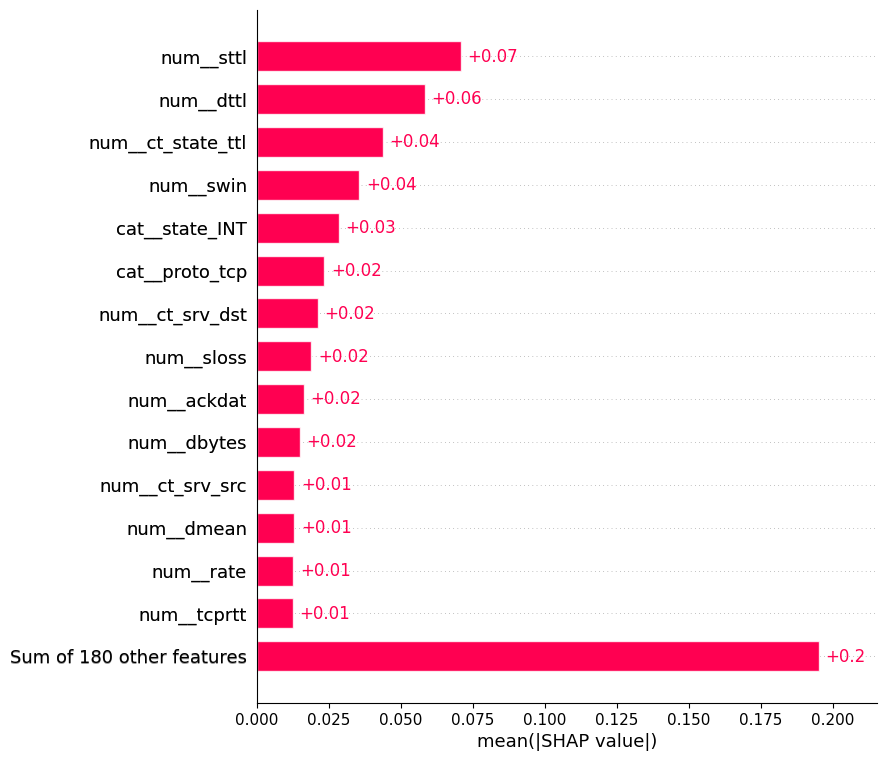

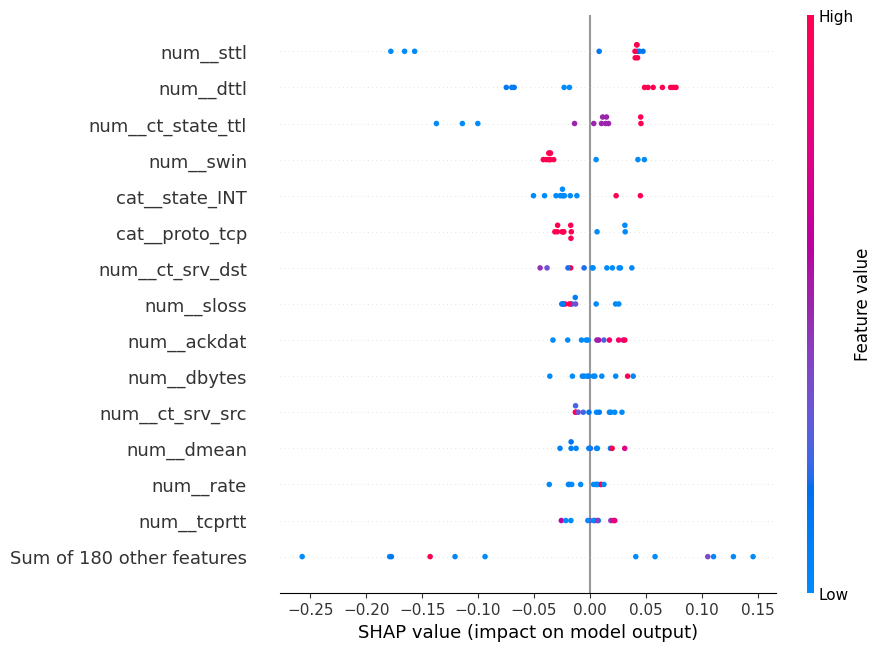

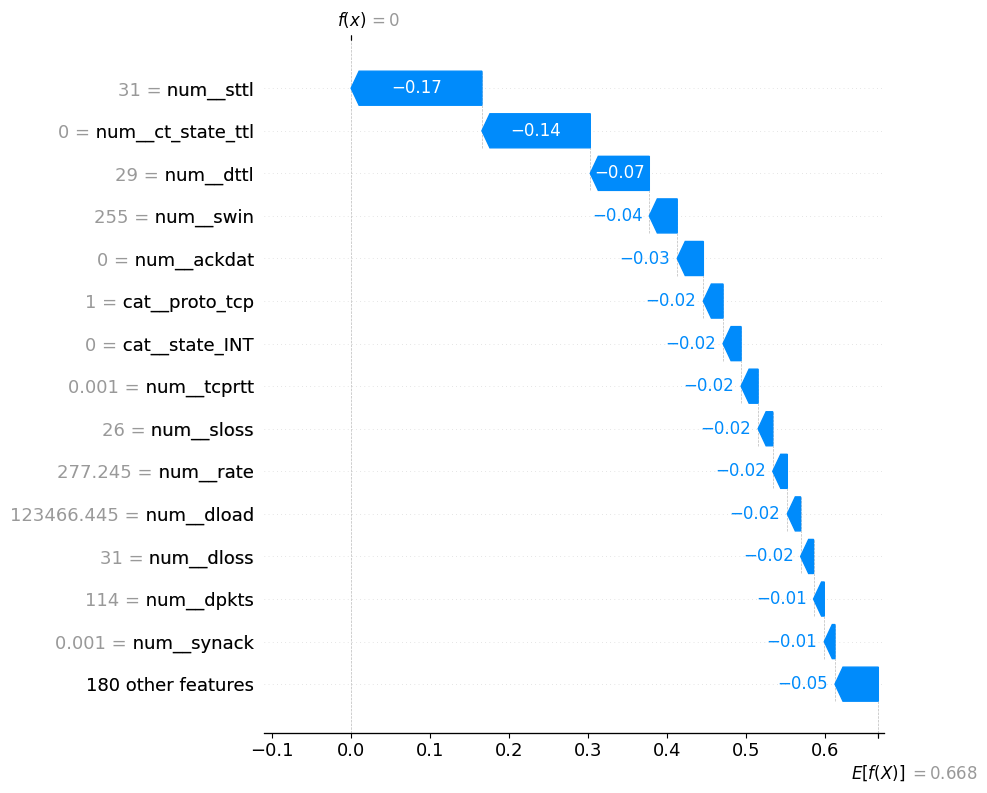

Maximum SHAP reconstruction difference: 9.992007221626409e-16
SHAP completed successfully.


In [15]:

import shap
from scipy import sparse
from sklearn.model_selection import train_test_split

# Use the validation-selected fitted pipeline
preprocessor = best_model.named_steps["preprocess"]
classifier = best_model.named_steps["model"]

_, X_shap_pool = train_test_split(
    X_train,
    test_size=0.035,
    stratify=y_train,
    random_state=SEED + 25
)

background_raw = X_shap_pool.iloc[:30]
explain_raw = X_shap_pool.iloc[30:42]

background = preprocessor.transform(background_raw)
X_explain = preprocessor.transform(explain_raw)

if sparse.issparse(background):
    background = background.toarray()

if sparse.issparse(X_explain):
    X_explain = X_explain.toarray()

background = np.asarray(background, dtype=float)
X_explain = np.asarray(X_explain, dtype=float)

try:
    feature_names = list(
        preprocessor.get_feature_names_out()
    )
except (AttributeError, ValueError):
    feature_names = [
        f"Encoded Feature {i}"
        for i in range(X_explain.shape[1])
    ]

assert len(feature_names) == X_explain.shape[1]

# Explain probability of Attack = 1
def predict_attack_probability(data):
    data = np.asarray(data, dtype=float)
    return classifier.predict_proba(data)[:, 1]

explainer = shap.Explainer(
    predict_attack_probability,
    background,
    feature_names=feature_names,
    algorithm="permutation"
)

shap_values = explainer(
    X_explain,
    max_evals=2 * X_explain.shape[1] + 1
)

print("SHAP model:", best_name)
print("Explained class: Attack = 1")
print("Explained samples:", len(X_explain))

# Global feature importance
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean absolute SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)
}).sort_values(
    "Mean absolute SHAP",
    ascending=False
)

display(shap_importance.head(15))

shap_importance.to_csv(
    OUT / "shap_global_importance.csv",
    index=False
)

# SHAP Bar Plot
shap.plots.bar(
    shap_values,
    max_display=15,
    show=False
)

plt.savefig(
    FIG / "shap_bar.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# SHAP Beeswarm Plot
shap.plots.beeswarm(
    shap_values,
    max_display=15,
    show=False
)

plt.savefig(
    FIG / "shap_beeswarm.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Local explanation for one sample
shap.plots.waterfall(
    shap_values[0],
    max_display=15,
    show=False
)

plt.savefig(
    FIG / "shap_waterfall.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

# Verify SHAP additive reconstruction
reconstructed = (
    np.asarray(shap_values.base_values)
    + np.asarray(shap_values.values).sum(axis=1)
)

actual = predict_attack_probability(X_explain)

print(
    "Maximum SHAP reconstruction difference:",
    float(np.max(np.abs(reconstructed - actual)))
)

assert np.allclose(
    reconstructed, actual, atol=0.02
)

print("SHAP completed successfully.")


## 12 — Save Reusable Results

In [16]:

# 12 — Save Reusable Results

# Save final test results and predictions
results.to_csv(
    OUT / "model_comparison.csv",
    index=False
)

pred_frame.to_csv(
    OUT / "test_predictions.csv",
    index=False
)

# Preserve validation-based model selection
selection_info = {
    "best_model": best_name,
    "selection_metric": "Validation F1",
    "validation_rows": int(len(X_val)),
    "official_test_rows": int(len(X_test)),
    "validation_f1": float(
        validation_results.set_index("Model")
        .loc[best_name, "F1-score"]
    ),
    "final_test_f1": float(
        results.set_index("Model")
        .loc[best_name, "F1-score"]
    ),
    "note": (
        "Model selected using validation F1. "
        "The official test set was used only "
        "for final evaluation."
    )
}

(OUT / "best_model.json").write_text(
    json.dumps(selection_info, indent=2),
    encoding="utf-8"
)

# Verify saved selection
saved_info = json.loads(
    (OUT / "best_model.json").read_text(
        encoding="utf-8"
    )
)

assert saved_info["best_model"] == best_name
assert saved_info["selection_metric"] == "Validation F1"

print("All results saved successfully.")
print("Selected model:", best_name)
print("Selection metric:", saved_info["selection_metric"])
print("Outputs directory:", OUT)
print("Notebook 03 can use these results.")


All results saved successfully.
Selected model: Random Forest
Selection metric: Validation F1
Outputs directory: /content/drive/MyDrive/CAI470_Project/outputs
Notebook 03 can use these results.
